
TEMPERATURE MODEL
-------------------------------------------------------
Tj                  : 75.0 deg C
Normalized RDS(on)  : 1.3000
RON typical at Tj   : 0.5200 ohm
RON maximum at Tj   : 0.7150 ohm

NONLINEAR COSS MODEL
-------------------------------------------------------
Raw digitized Qoss(50V) : 466.82 pC
Calibration correction : 5.327 pF
Model Qoss(50V)        : 600.00 pC
Model Coss(50V)        : 6.50 pF
Datasheet Coss(50V)    : 6.50 pF
Model Eoss(50V)        : 11.6482 nJ
Datasheet ER energy    : 11.8750 nJ
Model equivalent C_ER  : 9.319 pF


EPC2037 CLASS-E AMPLIFIER RESULTS

ANALYTICAL NETWORK
-----------------------------------------------------------------
KR                  : 0.576801
KC                  : 0.183601
KL                  : 1.152494
Ropt                : 8.2229 ohm
Csh ideal           : 253.8298 pF
C external          : 247.3298 pF
L1                  : 107.7349 nH
L2                  : 280.4392 nH
C2                  : 460.8349 pF

OPERATING POINT
-------

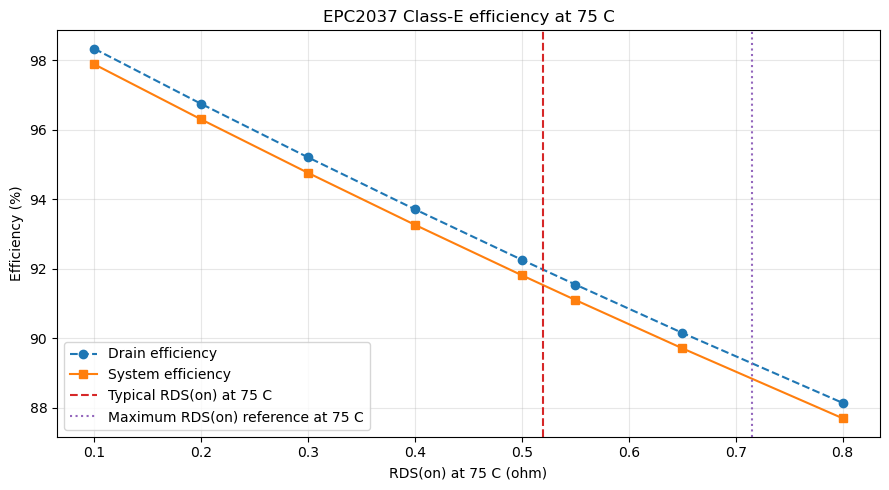

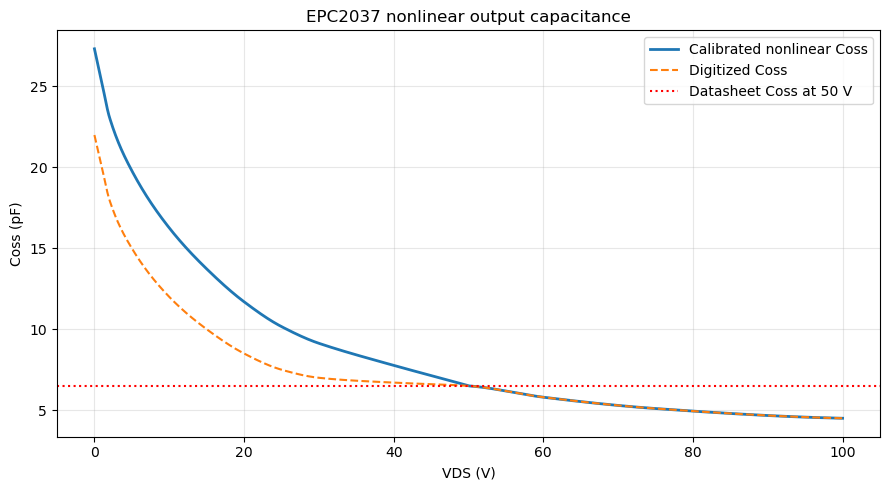

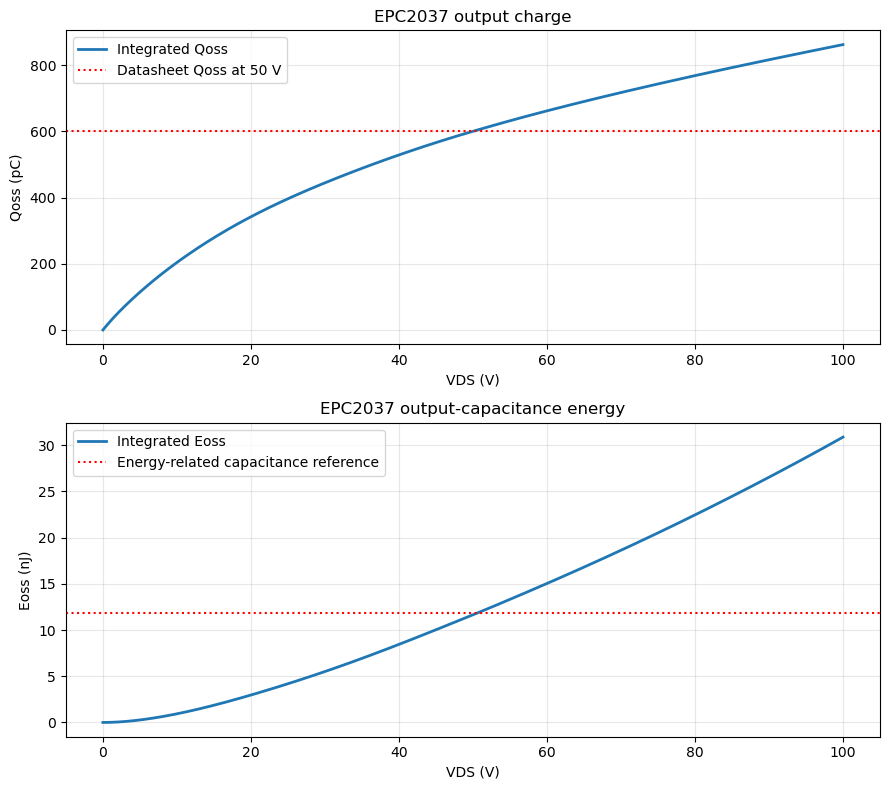

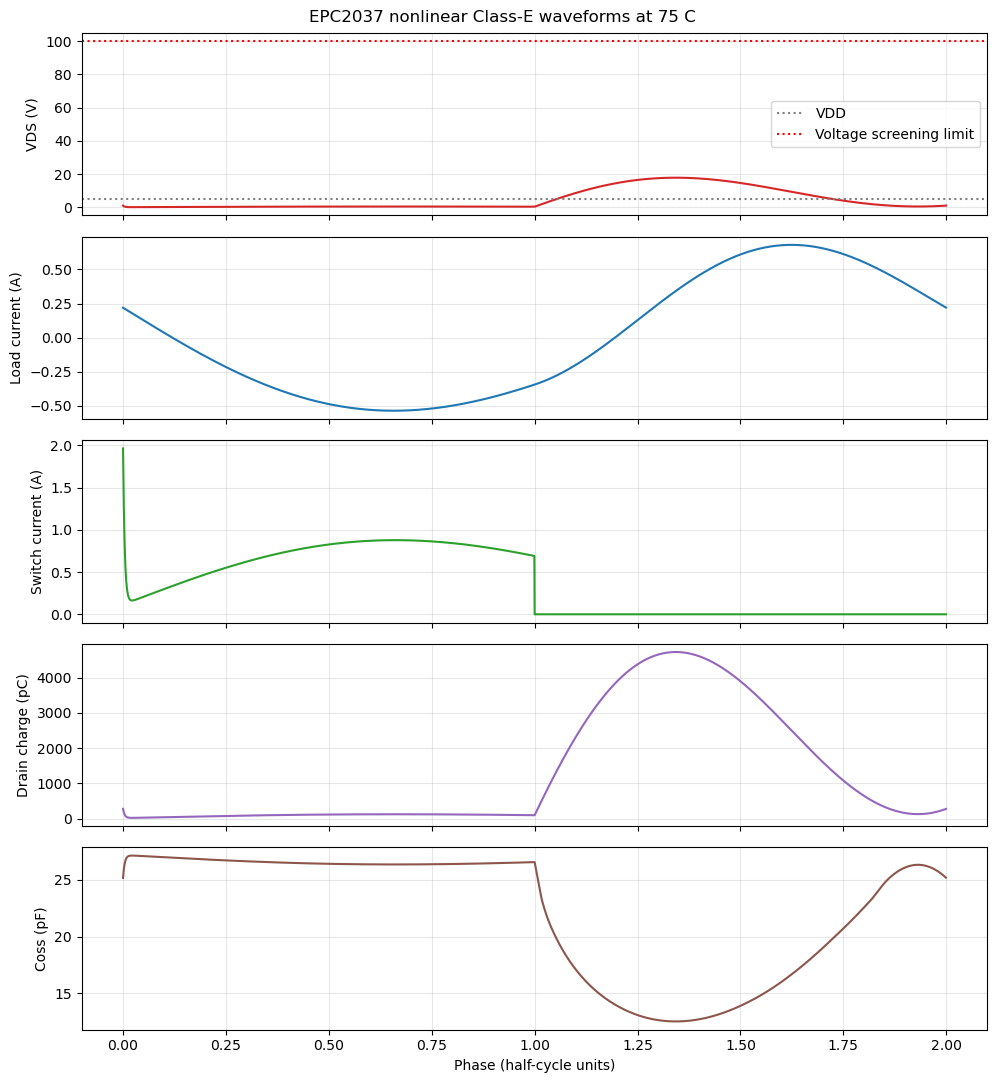

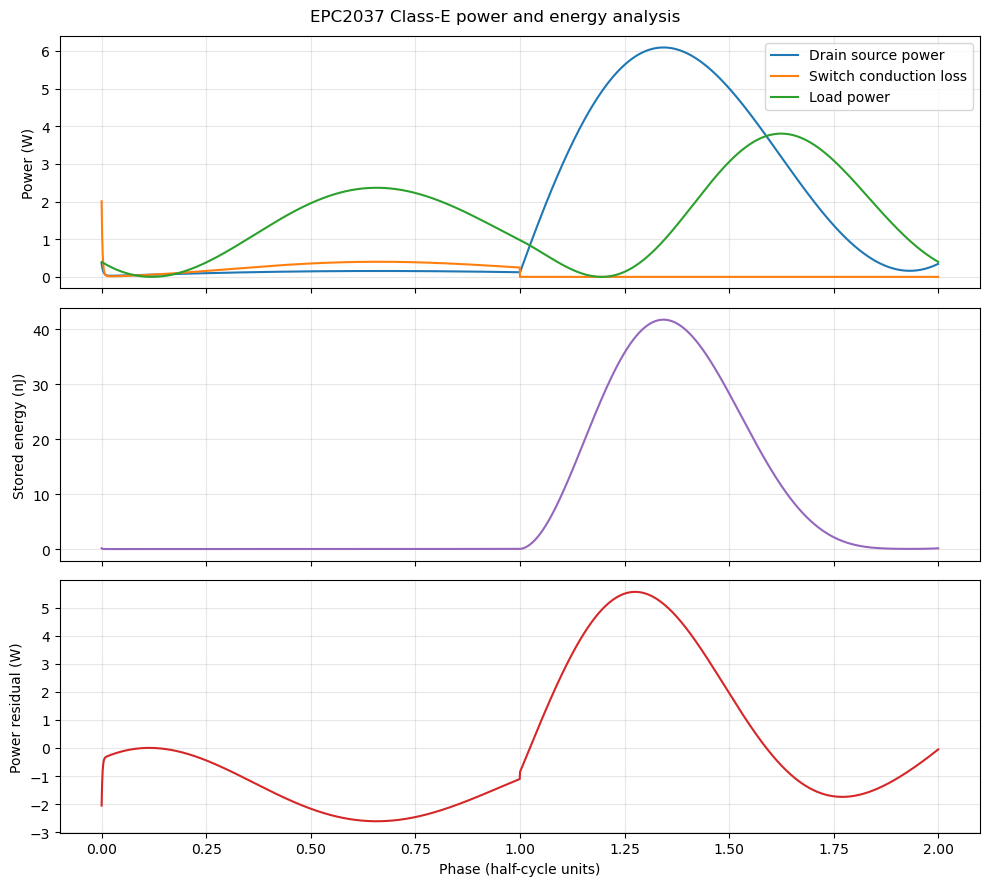

In [1]:

# ================================================================
# EPC2037 GaN CLASS-E AMPLIFIER
# Datasheet-based nonlinear behavioral model
#
# Operating point:
#   VDD = 4.85 V
#   Pout target = 1.65 W
#   f0 = 14 MHz
#   Tj = 75 deg C
#   VGS = 5 V
#
# Datasheet pages: EPC2037, supplied pages 2-4
#
# IMPORTANT:
#   Specified values and digitized approximations are distinguished.
#   This is a behavioral model, NOT a manufacturer SPICE model.
# ================================================================

import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp, cumulative_trapezoid
from scipy.optimize import brentq
from scipy.interpolate import PchipInterpolator


# ================================================================
# 1. OPERATING CONDITIONS
# ================================================================

VDD = 4.85
P_OUT_TARGET = 1.65
F0 = 14e6

W0 = 2*np.pi*F0
T = 1/F0
TH = T/2

TJ = 75.0
VG = 5.0

VDS_MAX = 100.0
ID_MAX = 1.7

# Existing model assumptions, not extracted from supplied pages.
RON_25 = 0.400
RON_MAX_25 = 0.550

# Datasheet typical values.
QG = 115e-12
QGS = 32e-12
QGD = 25e-12
RG = 0.5

P_GATE = QG*VG*F0


# ================================================================
# 2. EPC2037 DATASHEET PARAMETERS
# ================================================================

# Datasheet typical values.
CISS = 14e-12
CRSS = 0.1e-12
COSS_50 = 6.5e-12

COSS_ER = 9.5e-12
COSS_TR = 12e-12

QOSS_50 = 600e-12

# Datasheet maximum Qoss.
QOSS_50_MAX = 900e-12

# Datasheet maximum Coss.
COSS_50_MAX = 10e-12

# Existing model's maximum voltage/current limits are
# retained as simulation limits, not guaranteed SOA limits.


# ================================================================
# 3. TEMPERATURE-DEPENDENT RDS(ON)
# ================================================================

# Figure 8: normalized RDS(on) vs junction temperature.
#
# Approximate digitization of the supplied graph.
# Reference normalized value at 25 deg C = 1.0.

TJ_TABLE = np.array([
    0, 25, 50, 75, 100, 125, 150
], dtype=float)

RDS_NORMALIZED_TABLE = np.array([
    0.85, 1.00, 1.15, 1.30, 1.48, 1.65, 1.80
])

rds_temp_curve = PchipInterpolator(
    TJ_TABLE,
    RDS_NORMALIZED_TABLE,
    extrapolate=False
)

def temperature_factor(Tj):
    if Tj < 0 or Tj > 150:
        raise ValueError("Temperature outside digitized range.")

    return float(rds_temp_curve(Tj))


# The 0.4 ohm reference is the original model assumption.
# The temperature multiplier is approximated from Figure 8.

RON_TYP = RON_25 * temperature_factor(TJ)
RON_MAX = RON_MAX_25 * temperature_factor(TJ)

print("\nTEMPERATURE MODEL")
print("-"*55)
print(f"Tj                  : {TJ:.1f} deg C")
print(f"Normalized RDS(on)  : {temperature_factor(TJ):.4f}")
print(f"RON typical at Tj   : {RON_TYP:.4f} ohm")
print(f"RON maximum at Tj   : {RON_MAX:.4f} ohm")


# ================================================================
# 4. NONLINEAR COSS MODEL
# ================================================================

# Figure 5b: approximate digitization of Coss(VDS).
#
# These points are approximate graphical readings.
# They are NOT manufacturer tabulated values.
#
# The table is used as a differential capacitance characteristic.

V_COSS_RAW = np.array([
    0.0, 1.0, 2.0, 5.0, 10.0,
    15.0, 20.0, 25.0, 30.0,
    40.0, 50.0, 60.0, 75.0, 100.0
])

C_COSS_RAW = 1e-12*np.array([
    22.0, 20.0, 18.0, 15.0, 12.0,
    10.0, 8.5, 7.5, 7.0,
    6.7, 6.5, 5.8, 5.1, 4.5
])

coss_digitized = PchipInterpolator(
    V_COSS_RAW,
    C_COSS_RAW,
    extrapolate=False
)

# Dense voltage grid for numerical integration.
V_GRID = np.linspace(0, 100, 100001)

C_GRID_RAW = coss_digitized(V_GRID)

# Raw integrated charge.
Q_GRID_RAW = cumulative_trapezoid(
    C_GRID_RAW,
    V_GRID,
    initial=0
)

# Calibrate the low-voltage curve so that:
# Qoss(50V) = 600 pC
#
# Correction:
# C_corrected(V) = C_digitized(V) + A*(1 - V/50)
# for 0 <= V <= 50.
#
# This preserves Coss(50V) = 6.5 pF.

idx50 = np.argmin(np.abs(V_GRID-50.0))
Q_RAW_50 = Q_GRID_RAW[idx50]

CALIBRATION_A = (
    QOSS_50-Q_RAW_50
) / 25.0

C_GRID = C_GRID_RAW.copy()

mask = V_GRID <= 50.0

C_GRID[mask] += CALIBRATION_A * (
    1.0-V_GRID[mask]/50.0
)

if np.any(C_GRID <= 0):
    raise ValueError("Non-positive calibrated Coss.")

# Recalculate charge and energy from the same C(V).
Q_GRID = cumulative_trapezoid(
    C_GRID,
    V_GRID,
    initial=0
)

E_GRID = cumulative_trapezoid(
    V_GRID*C_GRID,
    V_GRID,
    initial=0
)

# Interpolation functions.
qoss_abs_curve = PchipInterpolator(
    V_GRID, Q_GRID
)

eoss_abs_curve = PchipInterpolator(
    V_GRID, E_GRID
)

coss_curve = PchipInterpolator(
    V_GRID, C_GRID
)


def coss(v):
    v = abs(float(v))
    return float(coss_curve(v))


def qoss(v):
    v = float(v)
    return np.sign(v)*float(qoss_abs_curve(abs(v)))


def eoss(v):
    return float(eoss_abs_curve(abs(float(v))))


# Datasheet energy-related capacitance reference.
# Eoss,ER = 0.5*Coss,ER*V^2

EOSS_ER_50 = 0.5*COSS_ER*50**2


print("\nNONLINEAR COSS MODEL")
print("-"*55)
print(f"Raw digitized Qoss(50V) : {Q_RAW_50*1e12:.2f} pC")
print(f"Calibration correction : {CALIBRATION_A*1e12:.3f} pF")
print(f"Model Qoss(50V)        : {qoss(50)*1e12:.2f} pC")
print(f"Model Coss(50V)        : {coss(50)*1e12:.2f} pF")
print(f"Datasheet Coss(50V)    : {COSS_50*1e12:.2f} pF")
print(f"Model Eoss(50V)        : {eoss(50)*1e9:.4f} nJ")
print(f"Datasheet ER energy    : {EOSS_ER_50*1e9:.4f} nJ")
print(f"Model equivalent C_ER  : {2*eoss(50)/50**2*1e12:.3f} pF")


# ================================================================
# 5. EXTERNAL SHUNT CAPACITANCE
# ================================================================

# Analytical ideal Class-E shunt capacitance.

a = 2/np.sqrt(np.pi**2+4)

phi = np.pi-np.arctan(2/np.pi)

KR = 2*a**2
KC = 2*a**2/np.pi

Ropt = KR*VDD**2/P_OUT_TARGET
Csh_ideal = KC/(W0*Ropt)

# The external capacitor is selected using the 50V
# differential Coss reference as an initial approximation.
#
# Note: this is a reference-value subtraction, not an
# exact equivalence of nonlinear capacitance.

C_EXTERNAL = Csh_ideal-COSS_50

if C_EXTERNAL <= 0:
    raise ValueError("External shunt capacitance is negative.")


def q_total(v):
    v = float(v)
    return C_EXTERNAL*v+qoss(v)


def e_total(v):
    v = float(v)
    return 0.5*C_EXTERNAL*v**2+eoss(v)


# Precompute inverse charge relation.
Q_TOTAL_GRID = (
    C_EXTERNAL*V_GRID+Q_GRID
)

def voltage_from_charge(q):
    q = float(q)

    if abs(q) < 1e-30:
        return 0.0

    if abs(q) > Q_TOTAL_GRID[-1]:
        raise ValueError(
            "Drain charge exceeds voltage interpolation range."
        )

    return np.sign(q)*np.interp(
        abs(q),
        Q_TOTAL_GRID,
        V_GRID
    )


# ================================================================
# 6. CLASS-E ANALYTICAL NETWORK
# ================================================================

IR_norm = np.sqrt(2/KR)
IDC_norm = a*IR_norm
C_norm = KC/KR

# Analytical drain waveform for calculating fundamental impedance.
th = np.linspace(0, 2*np.pi, 200001)

vd_norm = np.zeros_like(th)

off = th >= np.pi
x = th[off]

vd_norm[off] = (
    IDC_norm*(x-np.pi)
    + IR_norm*(
        np.cos(x+phi)-np.cos(np.pi+phi)
    )
)/C_norm

V1 = np.trapezoid(
    vd_norm*np.exp(-1j*th), th
)/np.pi

I1 = IR_norm*np.exp(
    1j*(phi-np.pi/2)
)

Z1 = V1/I1
KL = Z1.imag/Z1.real

L1 = KL*Ropt/W0


# ================================================================
# 7. OUTPUT TANK
# ================================================================

QL = 3.0

L2 = QL*Ropt/W0
C2 = 1/(W0**2*L2)

LT = L1+L2


# ================================================================
# 8. SWITCHING DIFFERENTIAL EQUATIONS
# ================================================================

# State:
# y = [Q_D, iL, v2]
#
# ON:
# dQ/dt = IDC - iL - iSW
#
# OFF:
# dQ/dt = IDC - iL
#
# iSW = vD/RDS(on)
#
# Gate transitions are idealized as instantaneous.
# Gate-drive energy is accounted for separately.

def make_on(IDC, RON):

    def f(t, y):

        q, iL, v2 = y

        vD = voltage_from_charge(q)

        iSW = vD/RON

        dq = IDC-iL-iSW

        diL = (
            vD-v2-Ropt*iL
        )/LT

        dv2 = iL/C2

        return [dq, diL, dv2]

    return f


def make_off(IDC):

    def f(t, y):

        q, iL, v2 = y

        vD = voltage_from_charge(q)

        dq = IDC-iL

        diL = (
            vD-v2-Ropt*iL
        )/LT

        dv2 = iL/C2

        return [dq, diL, dv2]

    return f


# ================================================================
# 9. PERIODIC STEADY-STATE SIMULATION
# ================================================================

def cycle(
    IDC,
    RON=RON_TYP,
    warmup=300,
    samples=1200
):

    if RON <= 0:
        raise ValueError("RON must be positive.")

    fon = make_on(IDC, RON)
    foff = make_off(IDC)

    y = np.zeros(3)

    rtol = 2e-8
    atol = 1e-12

    # Periodic convergence.
    for k in range(warmup):

        s1 = solve_ivp(
            fon,
            (0, TH),
            y,
            method="LSODA",
            rtol=rtol,
            atol=atol
        )

        if not s1.success:
            raise RuntimeError(s1.message)

        s2 = solve_ivp(
            foff,
            (0, TH),
            s1.y[:, -1],
            method="LSODA",
            rtol=rtol,
            atol=atol
        )

        if not s2.success:
            raise RuntimeError(s2.message)

        yn = s2.y[:, -1]

        error = np.max(np.abs(yn-y))

        y = yn

        if error < 1e-10:
            break

    # Final complete cycle.
    s1 = solve_ivp(
        fon,
        (0, TH),
        y,
        method="LSODA",
        rtol=rtol,
        atol=atol,
        dense_output=True
    )

    s2 = solve_ivp(
        foff,
        (0, TH),
        s1.y[:, -1],
        method="LSODA",
        rtol=rtol,
        atol=atol,
        dense_output=True
    )

    if not s1.success or not s2.success:
        raise RuntimeError("Final cycle integration failed.")

    t1 = np.linspace(
        0, TH, samples, endpoint=False
    )

    t2 = np.linspace(
        0, TH, samples, endpoint=False
    )

    y1 = s1.sol(t1)
    y2 = s2.sol(t2)

    q = np.r_[y1[0], y2[0]]
    iL = np.r_[y1[1], y2[1]]
    v2 = np.r_[y1[2], y2[2]]

    t = np.r_[t1, TH+t2]

    vD = np.array([
        voltage_from_charge(z) for z in q
    ])

    iSW = np.r_[
        vD[:samples]/RON,
        np.zeros(samples)
    ]

    v_avg = np.trapezoid(vD, t)/T

    return {
        "t": t,
        "q": q,
        "v_D": vD,
        "i_L": iL,
        "i_sw": iSW,
        "v2": v2,

        "v_avg": v_avg,
        "v_peak": np.max(vD),
        "v_min": np.min(vD),

        "v_turnon": voltage_from_charge(
            s2.y[0, -1]
        ),

        "i_turnon": s2.y[1, -1],

        "periodic_error": np.max(
            np.abs(s2.y[:, -1]-y)
        )
    }


# ================================================================
# 10. SELF-CONSISTENT OPERATING POINT
# ================================================================

def solve_operating_point(RON):

    def residual(IDC):

        h = cycle(
            IDC,
            RON=RON,
            warmup=300,
            samples=600
        )

        return h["v_avg"]-VDD

    lo = 0.05*P_OUT_TARGET/VDD
    hi = 3.0*P_OUT_TARGET/VDD

    flo = residual(lo)
    fhi = residual(hi)

    if flo*fhi > 0:

        raise RuntimeError(
            f"No IDC bracket for RON={RON:.4f} ohm. "
            f"Residuals: {flo:.5f}, {fhi:.5f}"
        )

    IDC = brentq(
        residual,
        lo,
        hi,
        xtol=1e-8
    )

    h = cycle(
        IDC,
        RON=RON,
        warmup=500,
        samples=1600
    )

    return h, IDC, h["v_avg"]-VDD


# ================================================================
# 11. POWER AND ENERGY ACCOUNTING
# ================================================================

def power_report(h, IDC, RON):

    t = h["t"]

    vD = h["v_D"]
    iL = h["i_L"]
    iSW = h["i_sw"]

    # DC supply input.
    P_IN = VDD*IDC

    # Actual drain-side DC source power.
    P_SOURCE_ACTUAL = np.trapezoid(
        vD*IDC, t
    )/T

    # Output load dissipation.
    P_LOAD = np.trapezoid(
        Ropt*iL**2, t
    )/T

    # Switch conduction loss.
    P_RON = np.trapezoid(
        RON*iSW**2, t
    )/T

    # External shunt capacitor energy.
    E_EXTERNAL = 0.5*C_EXTERNAL*vD**2

    # Nonlinear device output-capacitance energy.
    E_COSS = np.array([
        eoss(v) for v in vD
    ])

    E_CAP = E_EXTERNAL+E_COSS

    E_CAP_AVG = np.trapezoid(
        E_CAP, t
    )/T

    E_CAP_DELTA = E_CAP[-1]-E_CAP[0]

    # Energy balance of the modeled drain network.
    BALANCE = (
        P_SOURCE_ACTUAL-P_LOAD-P_RON
    )

    ETA_DRAIN = P_LOAD/P_IN

    ETA_SYSTEM = P_LOAD/(P_IN+P_GATE)

    # Difference between requested and simulated output.
    POUT_ERROR = P_LOAD-P_OUT_TARGET

    return {

        "P_in": P_IN,

        "P_source_actual": P_SOURCE_ACTUAL,

        "P_load": P_LOAD,

        "P_Ron": P_RON,

        "P_gate": P_GATE,

        "P_total": P_IN+P_GATE,

        "Pout_error": POUT_ERROR,

        "E_cap_avg": E_CAP_AVG,

        "E_cap_delta": E_CAP_DELTA,

        "balance": BALANCE,

        "eta_drain": ETA_DRAIN,

        "eta_system": ETA_SYSTEM
    }


# ================================================================
# 12. MAIN OPERATING POINT
# ================================================================

h, IDC, residual = solve_operating_point(RON_TYP)

p = power_report(
    h,
    IDC,
    RON_TYP
)

print("\n")
print("="*65)
print("EPC2037 CLASS-E AMPLIFIER RESULTS")
print("="*65)

print("\nANALYTICAL NETWORK")
print("-"*65)

print(f"KR                  : {KR:.6f}")
print(f"KC                  : {KC:.6f}")
print(f"KL                  : {KL:.6f}")

print(f"Ropt                : {Ropt:.4f} ohm")
print(f"Csh ideal           : {Csh_ideal*1e12:.4f} pF")
print(f"C external          : {C_EXTERNAL*1e12:.4f} pF")

print(f"L1                  : {L1*1e9:.4f} nH")
print(f"L2                  : {L2*1e9:.4f} nH")
print(f"C2                  : {C2*1e12:.4f} pF")

print("\nOPERATING POINT")
print("-"*65)

print(f"IDC                 : {IDC*1e3:.4f} mA")

print(f"Average drain V     : {h['v_avg']:.5f} V")

print(f"Peak drain voltage  : {h['v_peak']:.4f} V")
print(f"Minimum drain voltage: {h['v_min']:.4f} V")

print(f"Turn-on voltage     : {h['v_turnon']:.6f} V")

print(f"Turn-on current     : {h['i_turnon']:.6f} A")

print(f"Peak load current   : {np.max(h['i_L']):.5f} A")

print(f"Peak switch current : {np.max(h['i_sw']):.5f} A")


print(f"DC voltage residual : {residual*1e3:.6f} mV")
print(f"Periodic error      : {h['periodic_error']:.3e}")

print("\nPOWER ACCOUNTING")
print("-"*65)

for key in [
    "P_in",
    "P_source_actual",
    "P_load",
    "P_Ron",
    "P_gate",
    "P_total",
    "Pout_error",
    "balance"
]:
    print(f"{key:22s}: {p[key]*1e3:12.5f} mW")

print(f"\nDrain efficiency  : {p['eta_drain']*100:.4f} %")
print(f"System efficiency : {p['eta_system']*100:.4f} %")

print(
    f"Average capacitor energy: "
    f"{p['E_cap_avg']*1e9:.5f} nJ"
)


# ================================================================
# 13. DEVICE LIMIT CHECK
# ================================================================

print("\nDEVICE LIMIT CHECK")
print("-"*65)

print(
    f"VDS peak : {h['v_peak']:.3f} / "
    f"{VDS_MAX:.1f} V"
)

print(
    f"Load ID  : {np.max(h['i_L']):.3f} / "
    f"{ID_MAX:.2f} A"
)

print(
    f"Switch ID: {np.max(h['i_sw']):.3f} A"
)

print(
    "VDS screening: ",
    "PASS" if h["v_peak"] < VDS_MAX else "FAIL"
)

print(
    "Current screening: ",
    "PASS" if max(
        np.max(np.abs(h["i_L"])),
        np.max(np.abs(h["i_sw"]))
    ) < ID_MAX else "FAIL"
)


# ================================================================
# 14. ZERO-VOLTAGE SWITCHING CHECK
# ================================================================

print("\nZERO-VOLTAGE SWITCHING")
print("-"*65)

print(f"VDS at turn-on : {h['v_turnon']:.6f} V")
print(f"ID at turn-on  : {h['i_turnon']:.6f} A")

ZVS_LIMIT = 0.1

if abs(h["v_turnon"]) < ZVS_LIMIT:
    print("ZVS voltage criterion: PASS")
else:
    print("ZVS voltage criterion: FAIL")

# Also inspect the turn-on energy.
E_TURNON = e_total(h["v_turnon"])

print(
    f"Residual capacitor energy at turn-on: "
    f"{E_TURNON*1e9:.6f} nJ"
)


# ================================================================
# 15. RON SWEEP AT 75 DEG C
# ================================================================

ron_values = np.array([
    0.10,
    0.20,
    0.30,
    0.40,
    0.50,
    0.55,
    0.65,
    0.80
])

sweep = []

print("\nRON SWEEP AT 75 DEG C")
print("="*105)

print(
    f"{'RON':>7} "
    f"{'IDC(mA)':>10} "
    f"{'Vpk(V)':>9} "
    f"{'Pload(mW)':>12} "
    f"{'PRon(mW)':>12} "
    f"{'Balance(mW)':>13} "
    f"{'Drain(%)':>10} "
    f"{'System(%)':>11}"
)

for ron in ron_values:

    try:
        hs, ids, res = solve_operating_point(ron)

        ps = power_report(hs, ids, ron)

        sweep.append([
            ron,
            ids,
            hs["v_peak"],
            ps["P_load"],
            ps["P_Ron"],
            ps["balance"],
            ps["eta_drain"],
            ps["eta_system"]
        ])

        print(
            f"{ron:7.3f} "
            f"{ids*1e3:10.3f} "
            f"{hs['v_peak']:9.3f} "
            f"{ps['P_load']*1e3:12.3f} "
            f"{ps['P_Ron']*1e3:12.3f} "
            f"{ps['balance']*1e3:13.4f} "
            f"{ps['eta_drain']*100:10.3f} "
            f"{ps['eta_system']*100:11.3f}"
        )

    except (RuntimeError, ValueError) as exc:

        print(
            f"{ron:7.3f} "
            f"Simulation failed: {exc}"
        )

sweep = np.asarray(sweep)

if len(sweep) == 0:
    raise RuntimeError("No valid RON sweep operating points.")


# ================================================================
# 16. EFFICIENCY PLOT
# ================================================================

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    sweep[:, 0],
    100*sweep[:, 6],
    "o--",
    label="Drain efficiency"
)

ax.plot(
    sweep[:, 0],
    100*sweep[:, 7],
    "s-",
    label="System efficiency"
)

ax.axvline(
    RON_TYP,
    color="C3",
    ls="--",
    label="Typical RDS(on) at 75 C"
)

ax.axvline(
    RON_MAX,
    color="C4",
    ls=":",
    label="Maximum RDS(on) reference at 75 C"
)

ax.set(
    xlabel="RDS(on) at 75 C (ohm)",
    ylabel="Efficiency (%)",
    title="EPC2037 Class-E efficiency at 75 C"
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()


# ================================================================
# 17. NONLINEAR COSS CHARACTERISTIC
# ================================================================

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    V_GRID,
    C_GRID*1e12,
    linewidth=2,
    label="Calibrated nonlinear Coss"
)

ax.plot(
    V_GRID,
    C_GRID_RAW*1e12,
    "--",
    label="Digitized Coss"
)

ax.axhline(
    COSS_50*1e12,
    color="red",
    ls=":",
    label="Datasheet Coss at 50 V"
)

ax.set(
    xlabel="VDS (V)",
    ylabel="Coss (pF)",
    title="EPC2037 nonlinear output capacitance"
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()


# ================================================================
# 18. OUTPUT CHARGE AND ENERGY
# ================================================================

fig, ax = plt.subplots(2, 1, figsize=(9, 8))

# Output charge.
ax[0].plot(
    V_GRID,
    Q_GRID*1e12,
    linewidth=2,
    label="Integrated Qoss"
)

ax[0].axhline(
    QOSS_50*1e12,
    color="red",
    ls=":",
    label="Datasheet Qoss at 50 V"
)

ax[0].set(
    xlabel="VDS (V)",
    ylabel="Qoss (pC)",
    title="EPC2037 output charge"
)

ax[0].grid(alpha=0.3)
ax[0].legend()

# Output-capacitance energy.
ax[1].plot(
    V_GRID,
    E_GRID*1e9,
    linewidth=2,
    label="Integrated Eoss"
)

ax[1].axhline(
    EOSS_ER_50*1e9,
    color="red",
    ls=":",
    label="Energy-related capacitance reference"
)

ax[1].set(
    xlabel="VDS (V)",
    ylabel="Eoss (nJ)",
    title="EPC2037 output-capacitance energy"
)

ax[1].grid(alpha=0.3)
ax[1].legend()

plt.tight_layout()


# ================================================================
# 19. DRAIN VOLTAGE, LOAD CURRENT AND SWITCH CURRENT
# ================================================================

phase = h["t"]/TH

fig, ax = plt.subplots(
    5,
    1,
    figsize=(10, 11),
    sharex=True
)

# Drain voltage.
ax[0].plot(
    phase,
    h["v_D"],
    color="C3"
)

ax[0].axhline(
    VDD,
    color="gray",
    ls=":",
    label="VDD"
)

ax[0].axhline(
    VDS_MAX,
    color="red",
    ls=":",
    label="Voltage screening limit"
)

ax[0].set_ylabel("VDS (V)")
ax[0].grid(alpha=0.3)
ax[0].legend()

# Load current.
ax[1].plot(
    phase,
    h["i_L"],
    color="C0"
)

ax[1].set_ylabel("Load current (A)")
ax[1].grid(alpha=0.3)

# Switch current.
ax[2].plot(
    phase,
    h["i_sw"],
    color="C2"
)

ax[2].set_ylabel("Switch current (A)")
ax[2].grid(alpha=0.3)

# Drain charge.
ax[3].plot(
    phase,
    h["q"]*1e12,
    color="C4"
)

ax[3].set_ylabel("Drain charge (pC)")
ax[3].grid(alpha=0.3)

# Nonlinear Coss.
coss_wave = np.array([
    coss(v) for v in h["v_D"]
])

ax[4].plot(
    phase,
    coss_wave*1e12,
    color="C5"
)

ax[4].set_ylabel("Coss (pF)")
ax[4].set_xlabel("Phase (half-cycle units)")
ax[4].grid(alpha=0.3)

fig.suptitle(
    "EPC2037 nonlinear Class-E waveforms at 75 C"
)

plt.tight_layout()


# ================================================================
# 20. DRAIN POWER AND CAPACITOR ENERGY
# ================================================================

P_SOURCE_WAVE = IDC*h["v_D"]

P_SWITCH_WAVE = RON_TYP*h["i_sw"]**2

P_LOAD_WAVE = Ropt*h["i_L"]**2

E_CAP_WAVE = np.array([
    e_total(v) for v in h["v_D"]
])

fig, ax = plt.subplots(
    3,
    1,
    figsize=(10, 9),
    sharex=True
)

ax[0].plot(
    phase,
    P_SOURCE_WAVE,
    label="Drain source power"
)

ax[0].plot(
    phase,
    P_SWITCH_WAVE,
    label="Switch conduction loss"
)

ax[0].plot(
    phase,
    P_LOAD_WAVE,
    label="Load power"
)

ax[0].set_ylabel("Power (W)")
ax[0].grid(alpha=0.3)
ax[0].legend()

ax[1].plot(
    phase,
    E_CAP_WAVE*1e9,
    color="C4"
)

ax[1].set_ylabel("Stored energy (nJ)")
ax[1].grid(alpha=0.3)

ax[2].plot(
    phase,
    P_SOURCE_WAVE-P_SWITCH_WAVE-P_LOAD_WAVE,
    color="C3"
)

ax[2].set_ylabel("Power residual (W)")
ax[2].set_xlabel("Phase (half-cycle units)")
ax[2].grid(alpha=0.3)

fig.suptitle(
    "EPC2037 Class-E power and energy analysis"
)

plt.tight_layout()


# ================================================================
# 21. FINAL SUMMARY
# ================================================================

print("\n")
print("="*65)
print("FINAL EPC2037 CLASS-E SIMULATION SUMMARY")
print("="*65)

print(f"Frequency              : {F0/1e6:.3f} MHz")
print(f"Supply voltage         : {VDD:.3f} V")
print(f"Target output power    : {P_OUT_TARGET:.3f} W")
print(f"Gate voltage           : {VG:.2f} V")
print(f"Junction temperature   : {TJ:.1f} C")

print("-"*65)

print(f"Operating IDC          : {IDC*1e3:.3f} mA")
print(f"Actual output power    : {p['P_load']:.5f} W")

print(f"Peak drain voltage     : {h['v_peak']:.3f} V")
print(f"Peak load current      : {np.max(np.abs(h['i_L'])):.3f} A")
print(f"Peak switch current    : {np.max(np.abs(h['i_sw'])):.3f} A")

print(f"Turn-on drain voltage  : {h['v_turnon']:.6f} V")

print("-"*65)

print(f"Drain efficiency       : {p['eta_drain']*100:.3f} %")
print(f"System efficiency      : {p['eta_system']*100:.3f} %")

print(f"Switch conduction loss : {p['P_Ron']*1e3:.3f} mW")
print(f"Gate-drive power       : {p['P_gate']*1e3:.3f} mW")

print(f"Power balance residual : {p['balance']*1e3:.5f} mW")

print("="*65)

plt.show()
